# 403 - Object Detection

## Image Augmentation

In [2]:
import torch
import torchvision
from torch import nn
from PIL import Image
import matplotlib.pyplot as plt

%matplotlib inline

### Common Image Augmentation Methods

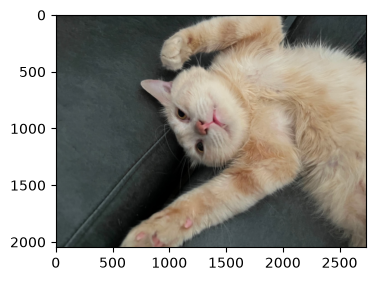

In [6]:
# Sample image
img = Image.open('assets/yuri.JPEG')
plt.figure(figsize=(4,4))
plt.imshow(img)
plt.show()

In [21]:
# Utility function to show results of augmentation
def apply(img, aug, num_rows=2, num_cols=4, scale=1.5):
    Y = [aug(img) for _ in range(num_rows * num_cols)]
    fig, axs = plt.subplots(num_rows, num_cols, figsize=(8,3), subplot_kw=dict(xticks=[], yticks=[]))
    for i,ax in enumerate(axs.flat):
        ax.imshow(Y[i])
    fig.tight_layout()
    plt.show()

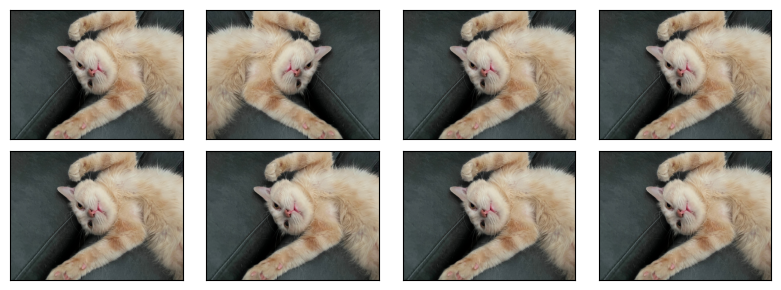

In [22]:
# Flipping and Cropping
apply(img, torchvision.transforms.RandomHorizontalFlip())

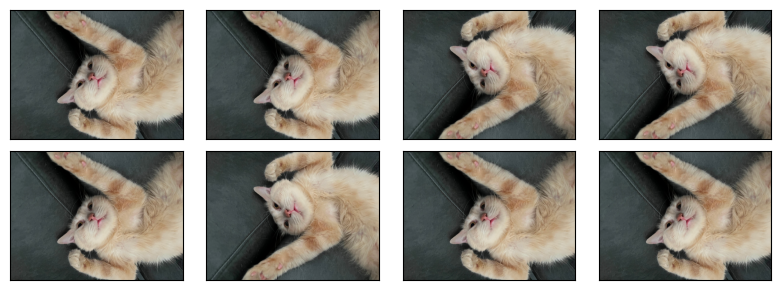

In [23]:
# vertical flip
apply(img, torchvision.transforms.RandomVerticalFlip())

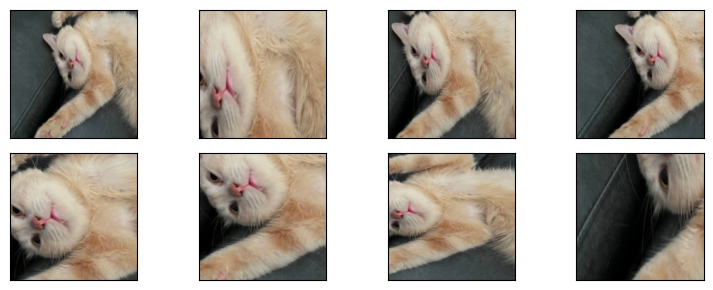

In [26]:
# random cropping and random resizing
reshape_crop = torchvision.transforms.RandomResizedCrop(
    size=(224,224), scale=(0.1,1), ratio=(0.5,2)
)
apply(img, reshape_crop)

There are four aspects that can be changed in an image:
1. Brightness
2. Contrast
3. Saturation
4. Hue

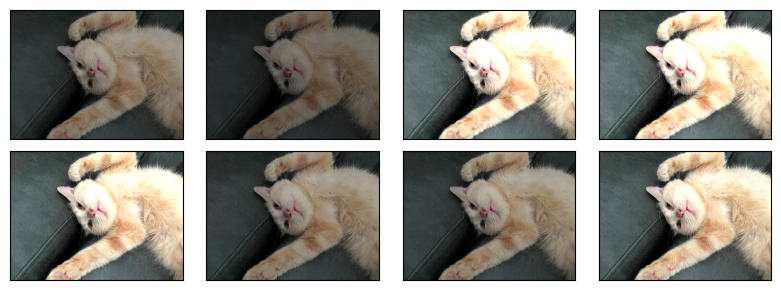

In [27]:
# Changing brightness randomly between 50% and 150%
apply(img, torchvision.transforms.ColorJitter(brightness=0.5))

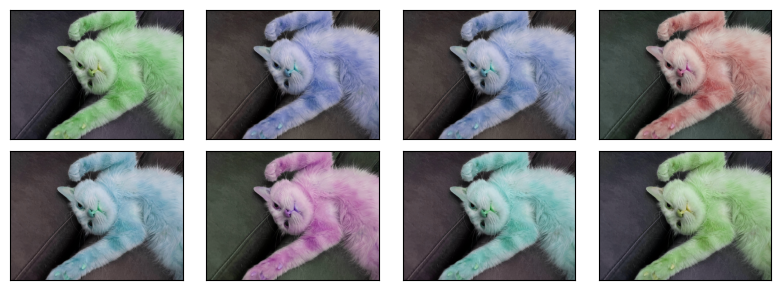

In [28]:
# Changing hue
apply(img, torchvision.transforms.ColorJitter(hue=0.5))

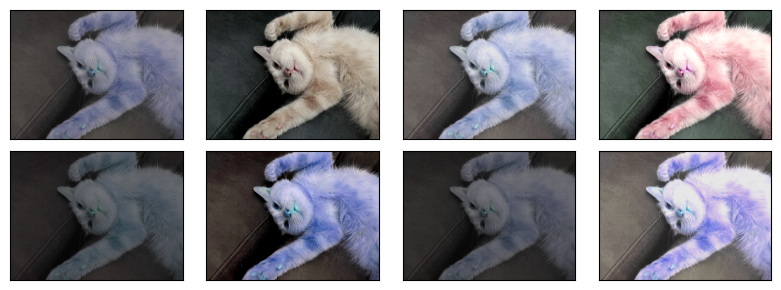

In [30]:
# All aspects
color_jitter = torchvision.transforms.ColorJitter(brightness=0.5, contrast=0.5, saturation=0.5, hue=0.5)
apply(img, color_jitter)

We can use `torchvision.transforms.Compose` to combine image transforms into a single transformer.

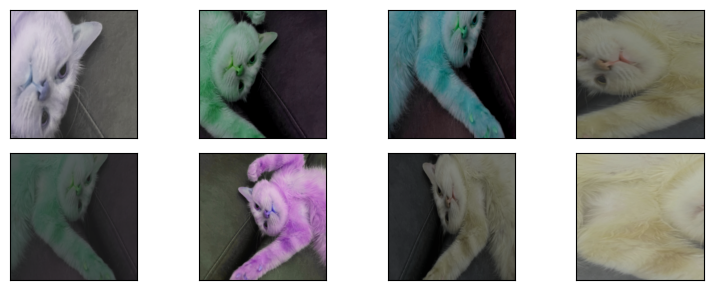

In [33]:
augs = torchvision.transforms.Compose([
    torchvision.transforms.RandomHorizontalFlip(), reshape_crop, color_jitter
])
apply(img, augs)

### Training with Image Augmentation

In [44]:
import torchvision.transforms.v2 as T
from torch.utils.data import DataLoader
from torchvision import datasets
from pathlib import Path
import numpy as np

# AUGMENTED CIFAR-10
# Load dataset
train_transform = T.Compose([T.RandomHorizontalFlip(),
                             T.ToImage(), 
                             T.ToDtype(torch.float32, scale=True)])
test_transform = T.Compose([T.ToImage(), T.ToDtype(torch.float32, scale=True)])
train_data = datasets.CIFAR10(root=Path.cwd().joinpath('data'), download=True, train=True, transform=train_transform)
test_data = datasets.CIFAR10(root=Path.cwd().joinpath('data'), download=True, train=False, transform=test_transform)

# Define loaders
torch.manual_seed(42)
cifar10_train_loader = DataLoader(train_data, batch_size=256, shuffle=True)
cifar10_test_loader = DataLoader(test_data, batch_size=256)

n_features = int(np.prod(tuple(train_data[0][0].shape)))
n_classes = len(train_data.classes)

print('------- CIFAR10 Dataset -------')
print(f'Image shape: {tuple(train_data[0][0].shape)}')
print(f'Classes: {train_data.classes}')
print(f'Training set: {len(train_data)}')
print(f'Test set: {len(test_data)}')

------- CIFAR10 Dataset -------
Image shape: (3, 32, 32)
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Training set: 50000
Test set: 10000


In [56]:
def train_mbgd(model, train_dataloader, test_dataloader, optimizer, criterion, metric_fn, n_epochs):
    history = {'loss': [], 'train_acc': [], 'test_acc': []}
    
    for epoch in range(n_epochs):
        training_loss = 0
        metric_fn.reset()
        for X_mb, y_mb in train_dataloader:
            # Training
            model.train()
            X_mb = X_mb.to('mps')
            y_mb = y_mb.to('mps')
            y_out = model(X_mb)
            loss = criterion(y_out, y_mb)
            training_loss += loss.detach().item()
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()

            # Accuracy on training data
            model.eval()
            with torch.no_grad():
                metric_fn.update(y_out, y_mb)

        training_acc = metric_fn.compute()
        training_loss /= len(train_dataloader)

        # Accuracy on test data
        metric_fn.reset()
        model.eval()
        for X_mb, y_mb in test_dataloader:
            with torch.no_grad():
                X_mb = X_mb.to('mps')
                y_mb = y_mb.to('mps')
                y_out = model(X_mb)
                metric_fn.update(y_out, y_mb)
        test_acc = metric_fn.compute()

        history['loss'].append(training_loss)
        history['train_acc'].append(training_acc.to('cpu'))
        history['test_acc'].append(test_acc.to('cpu'))
        
        print(f'Epoch {epoch + 1:03d}/{n_epochs} | loss: {training_loss:.3f} | train acc: {training_acc:.2%} | test acc: {test_acc:.2%}')

    return history

In [55]:
from torchmetrics import Accuracy

model = nn.Sequential(nn.Flatten(), nn.Linear(n_features,100), nn.ReLU(), nn.Linear(100, n_classes)).to('mps')
optimizer = torch.optim.SGD(model.parameters(), lr=0.05)
loss = nn.CrossEntropyLoss()
metric = Accuracy(task='multiclass', num_classes=n_classes).to('mps')

train_mbgd(model, cifar10_train_loader, cifar10_test_loader, optimizer, loss, metric, 10)

Epoch 001/10 | loss: 2.027 | train acc: 26.93% | test acc: 31.11%
Epoch 002/10 | loss: 1.857 | train acc: 34.19% | test acc: 31.69%
Epoch 003/10 | loss: 1.785 | train acc: 36.70% | test acc: 36.35%
Epoch 004/10 | loss: 1.742 | train acc: 38.48% | test acc: 37.84%
Epoch 005/10 | loss: 1.703 | train acc: 39.86% | test acc: 36.92%
Epoch 006/10 | loss: 1.670 | train acc: 40.84% | test acc: 38.16%
Epoch 007/10 | loss: 1.650 | train acc: 41.69% | test acc: 40.68%
Epoch 008/10 | loss: 1.625 | train acc: 42.69% | test acc: 42.74%
Epoch 009/10 | loss: 1.605 | train acc: 43.25% | test acc: 40.02%
Epoch 010/10 | loss: 1.589 | train acc: 44.11% | test acc: 41.21%


In [60]:
#Implemention ResNet-18
from functools import partial

# Residual unit - from previous notebook
class ResidualUnit(nn.Module):
    """
    restrictions:
     - padding is set to "same"
     - only two convolutions per unit
     - only the first convolution can have a stride > 1
     - fixed kernel size
    """
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        DefaultConv2d = partial(nn.Conv2d, kernel_size=3, stride=1, padding=1, bias=False)
        self.deep_stack = nn.Sequential(
            DefaultConv2d(in_channels=in_channels, out_channels=out_channels, stride=stride),
            nn.BatchNorm2d(num_features=out_channels),
            nn.ReLU(),
            DefaultConv2d(in_channels=out_channels, out_channels=out_channels),
            nn.BatchNorm2d(num_features=out_channels),
        )

        if stride > 1:
            self.wide_stack = nn.Sequential(
                nn.Conv2d(in_channels=in_channels, out_channels=out_channels, kernel_size=1, stride=stride, padding=0), 
                nn.BatchNorm2d(num_features=out_channels)
            )
        else:
            self.wide_stack = nn.Identity()
            
        self.output = nn.ReLU()
        
    def forward(self, X):
        Z = self.deep_stack(X) + self.wide_stack(X)
        return self.output(Z)

# ResNet-18
class ResNet18(nn.Module):
    def __init__(self):
        super().__init__()
        layers = [
            nn.Conv2d(3, 64, 7, 2, 3),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(3, 2)
        ]
        prev_filters = 64
        for filters in [64] * 2 + [128] * 2 + [256] * 2 + [512] * 2:
            stride = 1 if filters == prev_filters else 2
            layers.append(ResidualUnit(prev_filters, filters, stride=stride))
            prev_filters = filters
        layers += [
            nn.AdaptiveAvgPool2d(output_size=1),
            nn.Flatten(),
            nn.LazyLinear(10),
        ]
        self.resnet = nn.Sequential(*layers)

    def forward(self, X):
        return self.resnet(X)

In [61]:
ResNet18()

ResNet18(
  (resnet): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): ResidualUnit(
      (deep_stack): Sequential(
        (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU()
        (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
      (wide_stack): Identity()
      (output): ReLU()
    )
    (5): ResidualUnit(
      (deep_stack): Sequential(
        (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): 

In [85]:
# sanity check - does it actually have 18 conv/dense layers
counter = 0
for module in ResNet18().modules():
    if isinstance(module, (nn.Conv2d, nn.Linear)):
        counter += 1
        if isinstance(module, nn.Conv2d):
            kernel_size = module.kernel_size
            if kernel_size == (1, 1):
                counter -= 1

print(f'Conv2d and Dense layers: {counter}')

Conv2d and Dense layers: 18


In [92]:
torch.manual_seed(42)
model = ResNet18().to('mps')
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
loss = nn.CrossEntropyLoss()
metric = Accuracy(task="multiclass", num_classes=10).to('mps')
history_0_10 = train_mbgd(model, cifar10_train_loader, cifar10_test_loader, optimizer, loss, metric, 10)

Epoch 001/10 | loss: 1.384 | train acc: 50.20% | test acc: 55.37%
Epoch 002/10 | loss: 0.997 | train acc: 64.81% | test acc: 60.92%
Epoch 003/10 | loss: 0.853 | train acc: 69.96% | test acc: 60.90%
Epoch 004/10 | loss: 0.740 | train acc: 74.05% | test acc: 69.80%
Epoch 005/10 | loss: 0.660 | train acc: 76.75% | test acc: 71.21%
Epoch 006/10 | loss: 0.603 | train acc: 78.99% | test acc: 64.37%
Epoch 007/10 | loss: 0.556 | train acc: 80.45% | test acc: 62.19%
Epoch 008/10 | loss: 0.503 | train acc: 82.43% | test acc: 73.75%
Epoch 009/10 | loss: 0.466 | train acc: 83.70% | test acc: 67.26%
Epoch 010/10 | loss: 0.423 | train acc: 85.42% | test acc: 76.20%


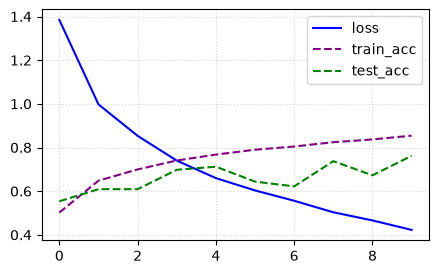

In [94]:
plt.figure(figsize=(5,3))
colors = ['blue', 'purple', 'green']
linestyles = ['-', '--', '--']
for color, ls, record in zip(colors, linestyles, history_0_10.items()):
    name, values = record
    plt.plot(range(len(values)), values, color=color, ls=ls, label=name)

plt.grid(visible=True, ls=":", alpha=0.5)
plt.legend()
plt.show()

In [95]:
# No augmentation
torch.manual_seed(42)
train_data_no_aug = datasets.CIFAR10(root=Path.cwd().joinpath('data'), download=True, train=True, transform=test_transform)
train_loader_no_aug = DataLoader(train_data_no_aug, batch_size=256, shuffle=True)
model = ResNet18().to('mps')
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
loss = nn.CrossEntropyLoss()
metric = Accuracy(task="multiclass", num_classes=10).to('mps')
history_0_10_no_aug = train_mbgd(model, train_loader_no_aug, cifar10_test_loader, optimizer, loss, metric, 10)

Epoch 001/10 | loss: 1.379 | train acc: 50.55% | test acc: 52.52%
Epoch 002/10 | loss: 0.995 | train acc: 64.69% | test acc: 61.32%
Epoch 003/10 | loss: 0.813 | train acc: 71.31% | test acc: 63.95%
Epoch 004/10 | loss: 0.702 | train acc: 75.31% | test acc: 62.64%
Epoch 005/10 | loss: 0.609 | train acc: 78.41% | test acc: 69.66%
Epoch 006/10 | loss: 0.526 | train acc: 81.61% | test acc: 68.53%
Epoch 007/10 | loss: 0.437 | train acc: 84.59% | test acc: 71.47%
Epoch 008/10 | loss: 0.364 | train acc: 87.26% | test acc: 71.77%
Epoch 009/10 | loss: 0.310 | train acc: 89.12% | test acc: 72.92%
Epoch 010/10 | loss: 0.259 | train acc: 90.92% | test acc: 71.61%


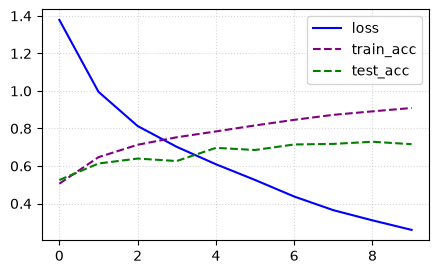

In [96]:
plt.figure(figsize=(5,3))
colors = ['blue', 'purple', 'green']
linestyles = ['-', '--', '--']
for color, ls, record in zip(colors, linestyles, history_0_10_no_aug.items()):
    name, values = record
    plt.plot(range(len(values)), values, color=color, ls=ls, label=name)

plt.grid(visible=True, ls=":", alpha=0.5)
plt.legend()
plt.show()

As expected, there is more overfitting when there are no augmentations.

In [106]:
# With more augmentations
torch.manual_seed(42)
train_transform = T.Compose([T.RandomHorizontalFlip(),
                             T.RandomResizedCrop(size=(32,32)),
                             T.ColorJitter(),
                             T.ToImage(), 
                             T.ToDtype(torch.float32, scale=True)])
train_data_more_aug = datasets.CIFAR10(root=Path.cwd().joinpath('data'), download=True, train=True, transform=train_transform)
train_loader_more_aug = DataLoader(train_data_more_aug, batch_size=256, shuffle=True)
model = ResNet18().to('mps')
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
loss = nn.CrossEntropyLoss()
metric = Accuracy(task="multiclass", num_classes=10).to('mps')
history_0_20_more_aug = train_mbgd(model, train_loader_more_aug, cifar10_test_loader, optimizer, loss, metric, 20)

Epoch 001/20 | loss: 2.112 | train acc: 25.51% | test acc: 11.09%
Epoch 002/20 | loss: 1.832 | train acc: 32.83% | test acc: 42.13%
Epoch 003/20 | loss: 1.694 | train acc: 37.80% | test acc: 41.65%
Epoch 004/20 | loss: 1.607 | train acc: 41.23% | test acc: 47.43%
Epoch 005/20 | loss: 1.508 | train acc: 45.43% | test acc: 47.99%
Epoch 006/20 | loss: 1.445 | train acc: 47.76% | test acc: 50.00%
Epoch 007/20 | loss: 1.386 | train acc: 50.22% | test acc: 52.58%
Epoch 008/20 | loss: 1.329 | train acc: 52.45% | test acc: 59.81%
Epoch 009/20 | loss: 1.282 | train acc: 54.18% | test acc: 53.00%
Epoch 010/20 | loss: 1.248 | train acc: 55.57% | test acc: 61.03%
Epoch 011/20 | loss: 1.206 | train acc: 57.24% | test acc: 64.81%
Epoch 012/20 | loss: 1.174 | train acc: 58.15% | test acc: 62.82%
Epoch 013/20 | loss: 1.143 | train acc: 59.50% | test acc: 67.25%
Epoch 014/20 | loss: 1.108 | train acc: 60.87% | test acc: 65.15%
Epoch 015/20 | loss: 1.104 | train acc: 61.15% | test acc: 38.30%
Epoch 016/

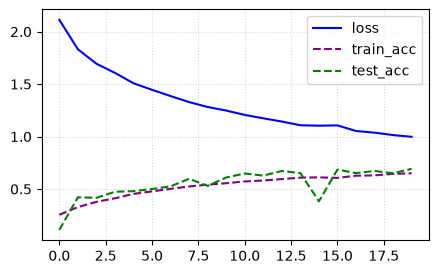

In [107]:
plt.figure(figsize=(5,3))
colors = ['blue', 'purple', 'green']
linestyles = ['-', '--', '--']
for color, ls, record in zip(colors, linestyles, history_0_20_more_aug.items()):
    name, values = record
    plt.plot(range(len(values)), values, color=color, ls=ls, label=name)

plt.grid(visible=True, ls=":", alpha=0.5)
plt.legend()
plt.show()

Adding more augmentations does improve the generalization performance. The learning rate should be increased due to the effects of regularization.

## Object Detection and Bounding Boxes

The goal of object detection is to (a) locate objects of interest in the image, and (b) classify the objects of interest.

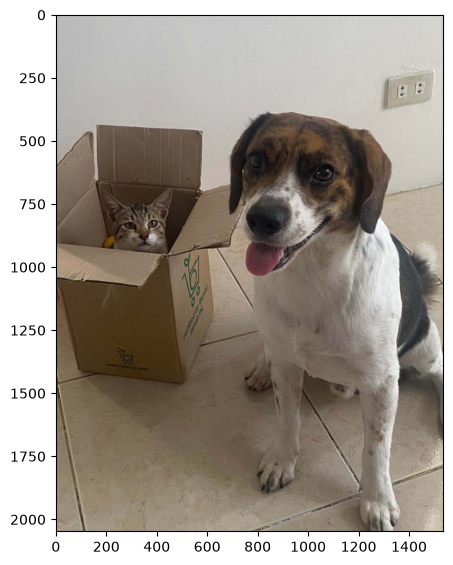

In [125]:
# Load image with cat (kento - RIP :( ... ) and dog (a young Teddy)
img_cat_dog = Image.open('assets/teddy_kento.JPEG')
plt.figure(figsize=(5,10))
plt.imshow(img_cat_dog)
plt.xticks(range(0,1500,200))
plt.show()

### Bounding boxes

In [337]:
# Define functions to convert between bounding box representations
def bbox_corner_to_center(boxes):
    """ Convert from (upper_left, lower_right) to (center, height, width)"""
    x1, y1, x2, y2 = [boxes[:, i] for i in range(boxes.shape[1])]
    xc = (x1 + x2)/2
    yc = (y1 + y2)/2
    height = torch.abs(y1 - y2)
    width = torch.abs(x1 - x2)
    bboxes_converted = torch.stack([xc, yc, height, width], axis=-1)
    return bboxes_converted

def bbox_center_to_corner(boxes):
    """ Convert from (center, height, width) to (upper_left, lower_right)"""
    xc, yc, height, width = [boxes[:, i] for i in range(boxes.shape[1])]
    x1 = xc - width/2
    x2 = xc + width/2
    y1 = yc - height/2
    y2 = yc + height/2
    bboxes_converted = torch.stack([x1, y1, x2, y2], axis=-1)
    return bboxes_converted

In [144]:
# Sample - bounding box for sample image of cat and dog
dog_bbox = [700, 375, 1500, 2000]
cat_bbox = [175, 700, 475, 950]
bboxes = torch.tensor((dog_bbox, cat_bbox))
bbox_center_to_corner(bbox_corner_to_center(bboxes)) == bboxes # verify correctness

tensor([[True, True, True, True],
        [True, True, True, True]])

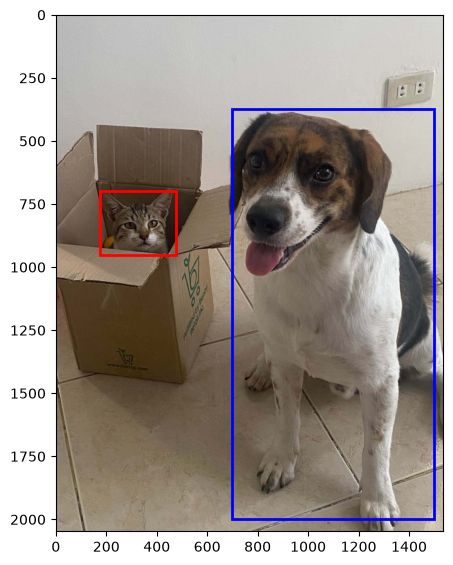

In [143]:
# Plot sample
import matplotlib as mpl
def bbox_to_rect(bbox, color):
    return mpl.patches.Rectangle(xy=(bbox[0], bbox[1]), width=bbox[2]-bbox[0], height=bbox[3]-bbox[1], fill=False, edgecolor=color, linewidth=2)

img_cat_dog = Image.open('assets/teddy_kento.JPEG')
fig,ax = plt.subplots(figsize=(5,10))
ax.imshow(img_cat_dog)
ax.add_patch(bbox_to_rect(dog_bbox, 'blue'))
ax.add_patch(bbox_to_rect(cat_bbox, 'red'))
plt.show()

## Anchor Boxes

### Generating Multiple Anchor Boxes

In [310]:
# Generating multiple anchor boxes
def multibox_prior(data, sizes, ratios):
    in_height, in_width = data.shape[-2:]
    device, num_sizes, num_ratios = data.device, len(sizes), len(ratios)
    boxes_per_pixel = num_sizes + num_ratios - 1
    size_tensor = torch.tensor(sizes, device=device)
    ratio_tensor = torch.tensor(ratios, device=device)
    
    # Center points for the anchor boxes
    # A pixel has height 1.0 and width 1.0
    offset_h, offset_w = 0.5, 0.5
    center_h = (torch.arange(in_height, device=device) + offset_h)/in_height
    center_w = (torch.arange(in_width, device=device) + offset_w)/in_width
    shift_y, shift_x = torch.meshgrid(center_h, center_w, indexing='ij')
    shift_y, shift_x = shift_y.reshape(-1), shift_x.reshape(-1)
    
    # Height and width of boxes
    w = torch.cat((size_tensor[0]*torch.sqrt(ratio_tensor), 
                   size_tensor[1:]*torch.sqrt(ratio_tensor[0]))) * in_height / in_width
    h = torch.cat((size_tensor[0] / torch.sqrt(ratio_tensor), 
                   size_tensor[1:] / torch.sqrt(ratio_tensor[0])))
    
    from_center = torch.stack((-w, -h, w, h)).T.repeat(in_height * in_width, 1) / 2
    out_grid = torch.stack([shift_x, shift_y, shift_x, shift_y], dim=1).repeat_interleave(boxes_per_pixel, dim=0)
    output = out_grid + from_center
    return output.unsqueeze(0)

In [309]:
# Bbox plotter
def show_bboxes(axes, bboxes, labels=None, colors=None):
    def make_list(obj, default_values=None):
        if obj is None:
            obj = default_values
        elif not isinstance(obj, (list, tuple)):
            obj = [obj]
        return obj

    labels = make_list(labels)
    colors = make_list(colors, ['b', 'g', 'r', 'm', 'c'])
    for i, bbox in enumerate(bboxes):
        color = colors[i % len(colors)]
        rect = bbox_to_rect(bbox.detach().numpy(), color)
        axes.add_patch(rect)
        if labels and len(labels) > i:
            text_color = 'k' if color == 'w' else 'w'
            axes.text(rect.xy[0], rect.xy[1], labels[i], 
                      va='center', ha='center', fontsize=9, color=text_color, 
                      bbox=dict(facecolor=color, lw=0))

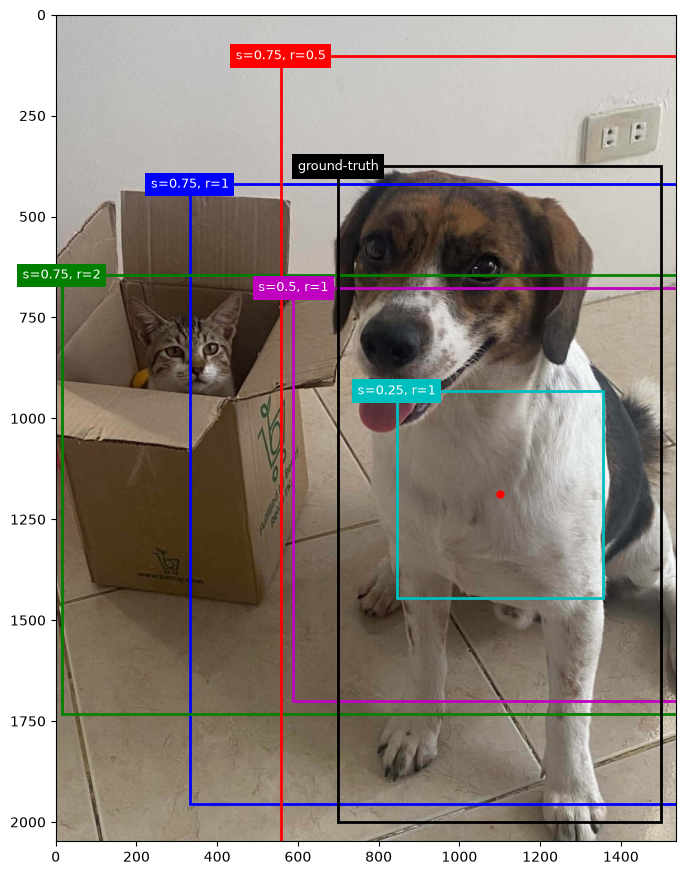

In [433]:
# Example: Plotting anchor boxes at pixel (1100, 1125)
import torchvision.transforms.v2 as T
toTensor = T.Compose([T.ToImage(), T.ToDtype(dtype=torch.float32, scale=True)])
data = toTensor(img_cat_dog)
h, w = data.shape[-2:]
sizes = [0.75, 0.5, 0.25]
ratios = [1, 2, 0.5]
boxes = multibox_prior(data, sizes, ratios).reshape(h, w, 5, 4)
bbox_scale = torch.tensor((w, h, w, h))

fig,ax = plt.subplots(figsize=(8,12))
ax.imshow(img_cat_dog)
ax.plot([1100], [1188], marker='o', markersize=5, ls='none', color='red')
show_bboxes(ax, boxes[1188, 1100, :, :] * bbox_scale, 
            ['s=0.75, r=1', 's=0.75, r=2', 's=0.75, r=0.5', 's=0.5, r=1', 's=0.25, r=1'])
show_bboxes(ax, torch.tensor([dog_bbox]), labels='ground-truth', colors='k')
ax.set_xlim(0,1536)
ax.set_ylim(2048,0)
plt.show()

### Intersection over Union

The *Jaccard index* is used to measure the similarity between two bounding boxes.
$$
\begin{align*}
    J(\mathcal{A}, \mathcal{B}) = \frac{\left| \mathcal{A} \cap \mathcal{B}\right|}{\left| \mathcal{A} \cup \mathcal{B}\right|}
\end{align*}
$$

It is the ratio of the area of the intersection and the area of the union (intersection over union).

<div align="center">
    <img src="assets/Screenshot 2026-11-17 at 3.39.29 PM.png" width=250>
</div>

In [405]:
bbox_pred = boxes[1100, 1188, :, :] * bbox_scale
bbox_true = torch.tensor([dog_bbox])
print(bbox_pred)
print(bbox_true)

def IoU(boxes1, boxes2):
    """Compute the area of intersection over area of union"""
    area_box = lambda box: (box[:, 2] - box[:, 0]) * (box[:, 3] - box[:, 1])
    
    intersect_upper_xy = torch.max(boxes1[:, None, :2], boxes2[None, :, :2])
    intersect_lower_xy = torch.min(boxes1[:, None, 2:], boxes2[None, :, 2:])
    intersect_hw = (intersect_lower_xy - intersect_upper_xy).clamp(min=0)
    area_intersection = intersect_hw[:, :, 0] * intersect_hw[:, :, 1]
    areas_1 = area_box(boxes1)
    areas_2 = area_box(boxes2)
    area_union = areas_1[:, None] + areas_2[None, :] - area_intersection
    return (area_intersection / area_union)

print('IoU:', IoU(bbox_pred, bbox_true))

tensor([[ 420.5000,  332.5000, 1956.4999, 1868.5000],
        [ 102.3840,  557.4420, 2274.6160, 1643.5581],
        [ 645.4420,   14.3839, 1731.5579, 2186.6162],
        [ 676.4999,  588.5000, 1700.5000, 1612.5000],
        [ 932.4999,  844.5000, 1444.5000, 1356.5000]])
tensor([[ 700,  375, 1500, 2000]])
IoU: tensor([[0.4848],
        [0.3114],
        [0.5510],
        [0.5356],
        [0.2016]])


### Assigning Ground-Truth Bounding Boxes to Anchor Bixes

In [428]:
B = torch.tensor((dog_bbox, cat_bbox))
A = boxes[[325, 1100], [825, 1188], :, :] * bbox_scale #two sets of anchor boxes, each centered at a different pixel
A = A.reshape(10, 4)
X = IoU(A, B)
j,i = torch.argmax(X, dim=0), torch.argmax(X, dim=1)
i,j

(tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0]), tensor([7, 0]))

In [429]:
X

tensor([[0.1864, 0.0318],
        [0.1210, 0.0212],
        [0.2336, 0.0202],
        [0.1436, 0.0202],
        [0.0531, 0.0000],
        [0.4848, 0.0056],
        [0.3114, 0.0318],
        [0.5510, 0.0000],
        [0.5356, 0.0000],
        [0.2016, 0.0000]])

In [427]:
X.shape

torch.Size([10, 2])